## <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>

##    <center>Curs 4b: Regresie liniară și predicție. Regularizarea regresiei</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/04-regresie/curs-04b-regularizarea-regresiei.ipynb)

In [1]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/04-regresie
sys.path.insert(0, os.path.abspath("../.."))

## Recapitulare
1. Regresie univariată
    - Antrenarea modelului și valori reziduale
    - Evaluarea performanței: Abaterea Pătratică Medie
    - Predicție versus inferență
2. Regresie multivariată (Regresie liniară multiplă)
    - Variabile categoriale în regresie
    - Valori extreme/aberante
    - Interpretarea ecuației de regresie

https://ds100.org/su21/resources/assets/lectures/lec17/lec17.html

Importuri necesare de module Python.

In [2]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,mean_absolute_percentage_error
import matplotlib.pyplot as plt

from sklearn.preprocessing import scale 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, RidgeCV, Lasso, LassoCV, LinearRegression

from sklearn.model_selection import KFold

Activăm grafica `inline`

In [3]:
%matplotlib inline

# Regularizare și utilizarea regresiei în predicție pe date mari

Două modele ies în evidență când regresia liniară este privită d.p.d.v. al învățării automate și tratată ca un model de învățare cu supervizare având ca scop predicția unei variabile numerice continue pe date mari.

## Lasso, Ridge  și hibridul dintre ele.

## Lasso (Least Absolute Shrinkage and Selection Operator) regression

## Validare încrucișată

# Setul de date de astăzi

Vânzări imobiliare din King county 
(<a href = "https://www.kaggle.com/datasets/feeldidaxie/king-county-house-sales-usa/data">link</a>).


In [4]:

df = pd.read_csv("./date/house_sales.csv", sep ="\t")

In [5]:
#df=df.dropna(how='any')
df.info()

<class 'pandas.DataFrame'>
Index: 22687 entries, 1 to 27063
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   DocumentDate     22687 non-null  str    
 1   SalePrice        22687 non-null  int64  
 2   PropertyID       22687 non-null  int64  
 3   PropertyType     22687 non-null  str    
 4   ym               22687 non-null  str    
 5   zhvi_px          22687 non-null  int64  
 6   zhvi_idx         22687 non-null  float64
 7   AdjSalePrice     22687 non-null  float64
 8   NbrLivingUnits   22687 non-null  int64  
 9   SqFtLot          22687 non-null  int64  
 10  SqFtTotLiving    22687 non-null  int64  
 11  SqFtFinBasement  22687 non-null  int64  
 12  Bathrooms        22687 non-null  float64
 13  Bedrooms         22687 non-null  int64  
 14  BldgGrade        22687 non-null  int64  
 15  YrBuilt          22687 non-null  int64  
 16  YrRenovated      22687 non-null  int64  
 17  TrafficNoise     22687 non-n

In [6]:
sorted(df.columns)

['AdjSalePrice',
 'Bathrooms',
 'Bedrooms',
 'BldgGrade',
 'DocumentDate',
 'ImpsVal',
 'LandVal',
 'NbrLivingUnits',
 'NewConstruction',
 'PropertyID',
 'PropertyType',
 'SalePrice',
 'SqFtFinBasement',
 'SqFtLot',
 'SqFtTotLiving',
 'TrafficNoise',
 'YrBuilt',
 'YrRenovated',
 'ZipCode',
 'ym',
 'zhvi_idx',
 'zhvi_px']

- DocumentDate: Date of the transaction.
- SalePrice: Sale price of the property.
- PropertyID: Unique identifier of the property.
- PropertyType: Type of property.
- ym: Year and month of the sale (format YYYY-MM).
- zhvi_px: Zillow Home Value Index (average price).
- zhvi_idx: Zillow Home Value Index (normalized).
- AdjSalePrice: Sale price adjusted for inflation.
- NbrLivingUnits: Number of residential units on the property.
- SqFtLot: Lot size (in square feet).
- SqFtTotLiving: Total living area (in square feet).
- SqFtFinBasement: Finished basement area (in square feet).
- Bathrooms: Total number of bathrooms.
- Bedrooms: Total number of bedrooms.
- BldgGrade: Overall quality of the building (1 to 13).
- YrBuilt: Year the building was constructed.
- YrRenovated: Year of the last renovation (0 if never renovated).
- TrafficNoise: Level of traffic-related noise.
- LandVal: Estimated value of the land.
- ImpsVal: Estimated value of improvements (buildings, structures).
- ZipCode: Postal code of the property.
- NewConstruction: Indicates whether the property is new construction (True/False).


`Observatie` Variabila țintă e prețul, <b>SalePrice</b>. Sunt multe atribute pe care nu le putem folosi - diverse IDuri (<i> PropertyID, zhvi_idx </i>), variabile de tip dată calendaristică - <i>DocumentDate</i>. Apoi codul poștal, mult prea granular, care nu poate fi folosit direct - eventual am putea vedea dacă din el se poate deriva zona folosind primele câteva cifre, dar nu este scopul lecției. Voi folosi un set prescurtat de predictori numerici din lista de mai sus. 

In [7]:
predictori = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'LandVal','ImpsVal','TrafficNoise','BldgGrade', 'PropertyType', 'NbrLivingUnits',
              'SqFtFinBasement', 'YrBuilt', 'YrRenovated', 
              'NewConstruction']

In [8]:
[c for c in set(df.columns).difference(set(predictori)) if df[c].dtype != object]

['DocumentDate',
 'PropertyID',
 'zhvi_px',
 'ym',
 'ZipCode',
 'SalePrice',
 'zhvi_idx',
 'AdjSalePrice']

<b>PropertyType</b> este categorial - să îl convertim cu one-hot-encoding:

In [9]:
df_final = pd.get_dummies(df[predictori+['SalePrice']])

In [10]:
df_final

,SqFtTotLiving,SqFtLot,Bathrooms,Bedrooms,LandVal,ImpsVal,TrafficNoise,BldgGrade,NbrLivingUnits,SqFtFinBasement,YrBuilt,YrRenovated,NewConstruction,SalePrice,PropertyType_Multiplex,PropertyType_Single Family,PropertyType_Townhouse
1,2400,9373,3.00,6,70000,229000,0,7,2,0,1991,0,False,280000,True,False,False
2,3764,20156,3.75,4,203000,590000,0,10,1,1452,2005,0,True,1000000,False,True,False
3,2060,26036,1.75,4,183000,275000,0,8,1,900,1947,0,False,745000,False,True,False
4,3200,8618,3.75,5,104000,229000,0,7,1,1640,1966,0,False,425000,False,True,False
5,1720,8620,1.75,4,104000,205000,0,7,1,0,1948,0,False,240000,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27057,1480,5468,1.75,3,201000,172000,0,7,1,590,1951,0,False,325000,False,True,False
27058,4720,23914,4.50,4,703000,951000,1,11,1,910,2000,0,False,1580000,False,True,False
27061,1070,11170,1.00,4,92000,130000,0,6,1,0,1971,0,False,165000,False,True,False
27062,1345,6223,2.00,3,103000,212000,0,7,1,0,1939,0,False,315000,False,True,False


In [11]:
df.PropertyType.unique()

<StringArray>
['Multiplex', 'Single Family', 'Townhouse']
Length: 3, dtype: str

`Observatie`Numărul de înregistrări nu e foarte mare, deci vom aplica rețeta de spargere specifică seturilor de date mici. Folosim 80% din date pentru antrenament și 20% pentru testul final. Pe datele de antrenament vom folosi o validare încrucișată pentru determinarea parametrul $\lambda$. 

Pentru a obține această proporție folosind validarea încrucișată, în câte părți vom sparge setul de date?

In [12]:
y = df_final['SalePrice']
X = df_final[[c for c in df_final.columns if c in predictori or 'PropertyType' in c]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)


In [13]:
lambda_values = 10**np.linspace(3,-3,10) # [ 9,6,7, 0.5]

print(min(lambda_values),max(lambda_values))

0.001 1000.0


In [14]:
np.linspace(-2,2,5)

array([-2., -1.,  0.,  1.,  2.])

In [15]:
10**np.linspace(2,-2,5)

array([1.e+02, 1.e+01, 1.e+00, 1.e-01, 1.e-02])

In [16]:
# 1. eliminare X_test, y_test din date
#- done

In [17]:
#Pasii 2-5 -> LassoCV
lambda_values = 10**np.linspace(3,-3,100) # [0.0001,0.01,0.1,1,10,100,1000]

lassocv = LassoCV(
        alphas = lambda_values, 
        cv = 10, 
        max_iter = 100000, 
        n_jobs = 10)

lassocv.fit(X_train, y_train)

#pas 5
lambda_optim = lassocv.alpha_

# pas 6: reantrenare pe toate datele de antrenament
lasso = Lasso(max_iter = 100000)
lasso.set_params(alpha=lambda_optim)

lasso.fit(X_train, y_train)

# pas 7 - raportatea erorii
y_hat_lasso_fit = lasso.predict(X_train)

print("R^2 pe date de antrenament: {:.2f}".format(lasso.score(X_train,y_train)))
print("MAE pe date antrenament: {:.2f}".format( mean_absolute_error(y_train, y_hat_lasso_fit )))
print("MAPE pe date antrenament: {:.2f}".format(100*mean_absolute_percentage_error(y_train, y_hat_lasso_fit )))

y_hat_lasso_test = lasso.predict(X_test)


print("MAE date test : {:.2f}".format( mean_absolute_error(y_test,y_hat_lasso_test)))
print("MAPE pe date antrenament {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_lasso_test )))

            

R^2 pe date de antrenament: 0.85
MAE pe date antrenament: 75303.14
MAPE pe date antrenament: 17.15
MAE date test : 73212.63
MAPE pe date antrenament 15.49


In [18]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)
y_hat_linreg_test = linreg.predict(X_test)
print("MAE pe date test (linreg): {:.2f}".format( mean_absolute_error(y_test, y_hat_linreg_test )))
print("MAPE pe date test (linreg): {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_linreg_test )))

MAE pe date test (linreg): 73414.82
MAPE pe date test (linreg): 15.54


Să vedem căți predictori a suprimat LASSO

In [19]:

df_coef = pd.DataFrame(lasso.coef_, index = X.columns).reset_index().rename(columns={'index':'Predictor',0:'Coeficient'})
print("LASSO a ales " + str(sum(df_coef.Coeficient != 0)) + " predictor(i) și a eliminat " +  \
      str(sum(df_coef.Coeficient == 0)) + " predictor(i)")

LASSO a ales 9 predictor(i) și a eliminat 7 predictor(i)


In [20]:
df_coef

,Predictor,Coeficient
0,SqFtTotLiving,37.694979
1,SqFtLot,0.328818
2,Bathrooms,0.000000
3,Bedrooms,-3388.047374
4,LandVal,0.941219
5,ImpsVal,0.730964
6,TrafficNoise,-0.000000
7,BldgGrade,0.000000
8,NbrLivingUnits,0.000000
9,SqFtFinBasement,-12.402334


Grafic cu importanta predictorilor:

În mărime absolută, și in condițiile în care predictorii au fost standardizați (deci toți iau valori în aceeși scală, comparabile), coeficienții determină importanța predictorilor - coeficient mare => importanță mare:

In [21]:
df_coef['Importanta_val_absoluta'] = abs(df_coef.Coeficient)
df_coef['Importanta'] = df_coef.Coeficient

In [22]:
import plotly.graph_objects as go

fig = go.Figure(go.Scatter(
            x=y_test, 
            y=lasso.predict(X_test),
            mode = 'markers'))
fig.add_trace(go.Scatter(
            x=y_test, 
            y=y_test,
            mode = 'lines'))
fig.update_layout( title = "Adevăr vs. Prognoză",
                 xaxis_title = 'Prețuri observate',
                 yaxis_title = 'Prețuri prognozate',
                 showlegend = False)
fig.show()

In [23]:
import plotly.graph_objects as go
df_to_plot = df_coef.sort_values(by = 'Importanta', ascending = False)
fig = go.Figure(go.Bar(
            x=df_to_plot.Importanta_val_absoluta,
            y=df_to_plot.Predictor,
            orientation='h'))

fig.update_layout( title = "Impactul Coefficienților în modelul Lasso")
fig.show()

In [24]:
fig = go.Figure(go.Bar(
            x=df_coef.sort_values(by = 'Importanta', ascending = False).Importanta,
            y=df_coef.sort_values(by = 'Importanta', ascending = False).Predictor,
            orientation='h'))

fig.update_layout( title = "Impactul Coefficienților în modelul Lasso")
fig.show()

## Efectul scalării

Vom folosi prima dată normalizarea, sau standardizarea, care în sklearn este numit StandardScaler.
- $\sigma$ este deviația standard
- $\mu$ este media

Cu <b>ipoteza</b> (de multe ori neverificată) că datele provin dintr-o <b>distribuție normală</b>, se încearcă transformarea acestei distribuții într-o distribuție cu medie $0$ și deviație standard $1$. În acest scop se centrează datele și se împarte la deviația standard:
\begin{equation}
\large X_{scalat} = \frac{X-\mu}{\sigma} 
\end{equation}


    

In [25]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler = StandardScaler() # valori implicite: copy=True, with_mean=True, with_std=True)
minmax_scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
#Pasii 2-5 -> LassoCV
lambda_values = 10**np.linspace(5,-5,100) # [0.0001,0.01,0.1,1,10,100,1000]
# normalize = True pentru ca toti predictorii sa fie normalizati la aceeiasi scala
lassocv_scalat = LassoCV(
        alphas = lambda_values, 
        cv = 10, 
        max_iter = 100000, 
        n_jobs = 10)

lassocv_scalat.fit(X_train_scaled, y_train)

#pas 5
lambda_optim_scalat = lassocv_scalat.alpha_

# pas 6: reantrenare pe toate datele de antrenament
lasso_scalat = Lasso(max_iter = 100000)
lasso_scalat.set_params(alpha=lambda_optim_scalat)
lasso_scalat.fit(X_train_scaled, y_train)

# pas 7 - raportatea erorii
y_hat_lasso_fit =  lasso_scalat.predict(X_train_scaled)
y_hat_lasso_test = lasso_scalat.predict(X_test_scaled)

print("R^2 pe date de anternament: {:.2f}".format(lasso_scalat.score(X_train_scaled,y_train)))
print("MAE pe date antrenatemant: {:.2f}".format( mean_absolute_error(y_train, y_hat_lasso_fit )))
print("MAPE pe date nantrenatemant: {:.2f}".format(100*mean_absolute_percentage_error(y_train, y_hat_lasso_fit )))



print("\nR^2 pe date de test: : {:.2f}".format(lasso_scalat.score(X_test_scaled,y_test)))
print("MAE date test : {:.2f}".format( mean_absolute_error(y_test,y_hat_lasso_test)))
print("MAPE pe date antrenatemant {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_lasso_test )))

            

R^2 pe date de anternament: 0.85
MAE pe date antrenatemant: 75342.18
MAPE pe date nantrenatemant: 17.16

R^2 pe date de test: : 0.86
MAE date test : 73244.58
MAPE pe date antrenatemant 15.50


R^2 pe date de antrenament: 0.85
MAE pe date antrenament: 74686.43
MAPE pe date antrenament: 16.86
MAE date test : 74757.76
MAPE pe date antrenament 16.45

## Coeficienți pentru modelul cu date de antrenament scalate

In [27]:
df_coef_scalat = pd.DataFrame(lasso_scalat.coef_, index = X.columns).reset_index().rename(columns={'index':'Predictor',0:'Coeficient'})
print("LASSO a ales " + str(sum(df_coef_scalat.Coeficient != 0)) + " predictor(i) și a eliminat " +  \
      str(sum(df_coef_scalat.Coeficient == 0)) + " predictor(i)")

LASSO a ales 12 predictor(i) și a eliminat 4 predictor(i)


In [28]:
import plotly.graph_objects as go
df_coef_scalat['Importanta_val_absoluta'] = abs(df_coef_scalat.Coeficient)
df_coef_scalat['Importanta'] = df_coef_scalat.Coeficient
fig = go.Figure()
fig.add_trace(go.Bar(
            x=df_coef_scalat.sort_values(by = 'Importanta', ascending = False).Importanta,
            y=df_coef_scalat.sort_values(by = 'Importanta', ascending = False).Predictor,
            orientation='h'))

fig.update_layout( title = "Impactul Coefficienților în modelul Lasso")
fig.show()

## Care sunt diferențele?
De ce a crescut valoarea coeficienților pentru ImpsVal, LandVal?
S-a modificat puterea de predicție?

In [29]:
display(X_train[["ImpsVal","LandVal","NewConstruction"]].head())
pd.DataFrame(X_train_scaled, columns = X_train.columns)[["ImpsVal","LandVal","NewConstruction"]].head()

,ImpsVal,LandVal,NewConstruction
26746,907000,294000,False
11311,277000,252000,False
3525,295000,138000,False
26186,126000,65000,False
25482,685000,440000,False


,ImpsVal,LandVal,NewConstruction
0,2.689639,0.407337,-0.342252
1,-0.102789,0.176285,-0.342252
2,-0.023006,-0.450856,-0.342252
3,-0.772086,-0.852446,-0.342252
4,1.705640,1.210518,-0.342252


<Axes: >

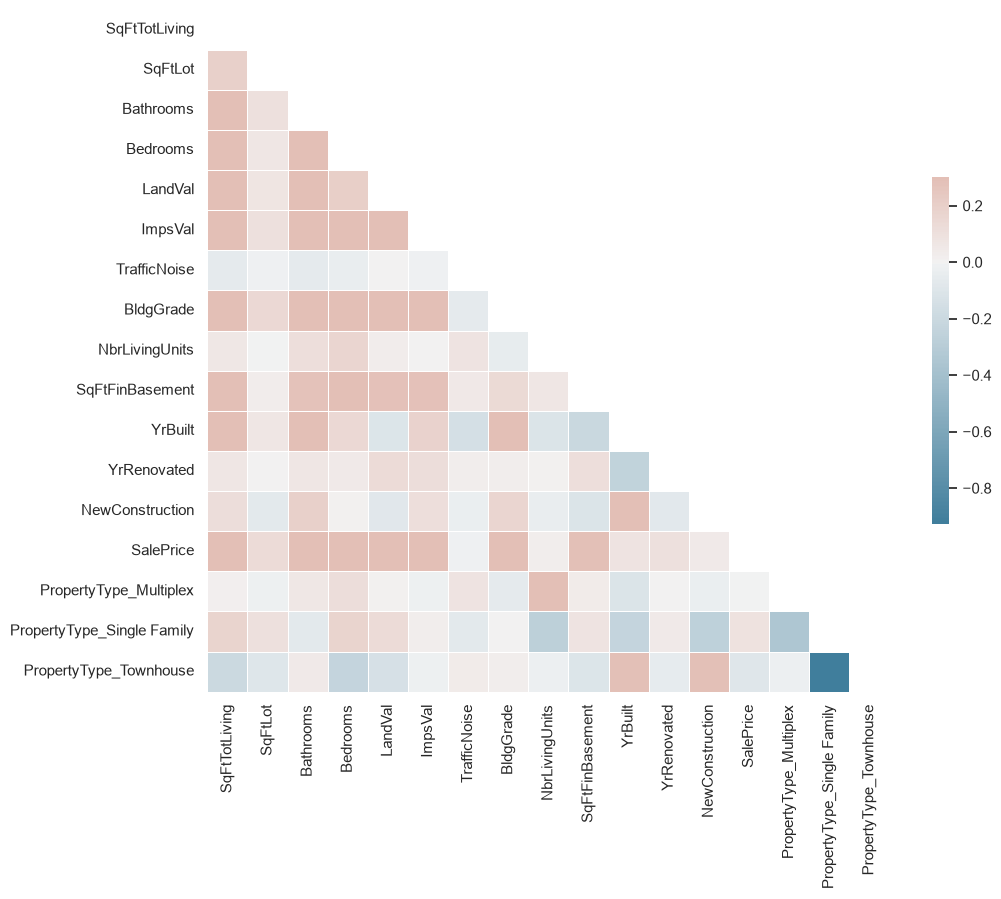

In [30]:
from string import ascii_letters
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="white")

d = df_final #X_train

# Compute the correlation matrix
corr = d.corr()

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=.3, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

In [31]:
X_train_scaled

array([[ 3.63879919,  0.7770893 ,  3.02806303, ..., -0.10475547,
         0.30858808, -0.28698302],
       [-0.16103243, -0.1431632 ,  0.42383771, ..., -0.10475547,
         0.30858808, -0.28698302],
       [ 0.72595997, -0.14141197,  0.74936587, ..., -0.10475547,
         0.30858808, -0.28698302],
       ...,
       [-0.48954813, -0.13116895,  0.09830954, ..., -0.10475547,
         0.30858808, -0.28698302],
       [ 0.11273066, -0.22404999,  0.42383771, ..., -0.10475547,
         0.30858808, -0.28698302],
       [-0.6647565 , -0.15132457, -1.52933128, ..., -0.10475547,
         0.30858808, -0.28698302]], shape=(18149, 16))

In [32]:
X_train_scaled[ [list(X_train.columns).index(c) for c in ["ImpsVal","LandVal","NewConstruction"] ] ]

array([[ 0.18938432,  1.26799416,  0.42383771,  0.69845641, -0.15378915,
        -0.30224856, -0.3727439 ,  0.27303762, -0.11453702, -0.66740931,
         0.88574761, -0.23239503, -0.34225214, -0.10475547,  0.30858808,
        -0.28698302],
       [ 3.04747093, -0.02721885,  1.72595037,  1.80007156,  1.21051764,
         1.70564045, -0.3727439 ,  2.80774849, -0.11453702,  1.74053947,
         0.91871798, -0.23239503, -0.34225214, -0.10475547,  0.30858808,
        -0.28698302],
       [-0.32529028, -0.11266544, -0.55274679, -0.40315873,  0.02775168,
        -0.10278939, -0.3727439 , -0.571866  , -0.11453702,  1.35435901,
        -0.99356396, -0.23239503, -0.34225214, -0.10475547,  0.30858808,
        -0.28698302]])

In [33]:
display(X_train[["ImpsVal","LandVal","NewConstruction"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
ImpsVal,18149.0,300190.322552,225616.295746,0.0,171000.0,245000.0,359000.0,4846000.0
LandVal,18149.0,219955.375337,181782.304807,0.0,107000.0,182000.0,267000.0,5538000.0


In [34]:
X_train.groupby('NewConstruction').count()

,SqFtTotLiving,SqFtLot,Bathrooms,Bedrooms,LandVal,ImpsVal,TrafficNoise,BldgGrade,NbrLivingUnits,SqFtFinBasement,YrBuilt,YrRenovated,PropertyType_Multiplex,PropertyType_Single Family,PropertyType_Townhouse
NewConstruction,,,,,,,,,,,,,,,
False,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246,16246
True,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903,1903


In [35]:
col_idxs = [list(X_train.columns).index(c) for c in ["ImpsVal","LandVal","NewConstruction"]]
df = pd.DataFrame()
for c in ["ImpsVal","LandVal","NewConstruction"]:
    
    i = list(X_train.columns).index(c)
    colname = str(X_train.columns[i])
    df[colname] = pd.Series(X_train_scaled[i])
    
    
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ImpsVal,16.0,0.091871,0.523285,-0.667409,-0.290799,-0.109646,0.337400,1.267994
LandVal,16.0,0.861522,1.162605,-0.372744,-0.144002,0.613653,1.729598,3.047471
NewConstruction,16.0,-0.176566,0.500623,-0.993564,-0.380348,-0.259689,-0.104264,1.354359


<b>Concluzie</b> În datele nescalate valorile coeficienților depind de scalele variabilelor: mărimea coeficienților scade cu creșterea ordinului de mărime la variabile.

`info` Probleme cu normalizarea:
<img style="float: center; padding-right: 10px; width: 500px; " src="https://raw.githubusercontent.com/sbildea/SEED/main/cursuri/04-regresie/imagini/cvartetul_Anscombe.png"  ><center><b>Fig. Cvartetul lui Anscombe - patru seturi de date cu aceeiași medie și deviație standard</b> (Credits <a href ="https://en.wikipedia.org/wiki/Anscombe%27s_quartet" >wiki</a>)</center>

## Dar dacă folosim altă scalare?

Formula pentru scalare min-max:

 - $min$ este minimul șirului de numere
 - $Max$ este maximul șirului de numere
 - $x$ este un element oarecare al șirului
 
 Vrem ca toate valorile șirului să fie mapate în intervalul $[0, 1 ]$.
 
\begin{equation}
\large x_{scalat} = \frac{x-min}{Max-min} 
\end{equation}
Care e diferența între scalarea precedentă și MinMaxScaler?

In [36]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler2 = MinMaxScaler()
X_train_scaled2 = scaler2.fit_transform(X_train)
X_test_scaled2 = scaler2.transform(X_test)

In [37]:
#Pasii 2-5 -> LassoCV
lambda_values = 10**np.linspace(5,-5,100) # [0.0001,0.01,0.1,1,10,100,1000]
# normalize = True pentru ca toti predictorii sa fie normalizati la aceeiasi scala
lassocv_scalat2 = LassoCV(
        alphas = lambda_values, 
        cv = 10, 
        max_iter = 100000, 
        n_jobs = 10)

lassocv_scalat2.fit(X_train_scaled2, y_train)

#pas 5
lambda_optim_scalat2 = lassocv_scalat2.alpha_

# pas 6: reantrenare pe toate datele de antrenament
lasso_scalat2 = Lasso(max_iter = 100000)#, normalize = True)
lasso_scalat2.set_params(alpha=lambda_optim_scalat2)
lasso_scalat2.fit(X_train_scaled2, y_train)


# pas 7 - raportarea erorii
y_hat_lasso_fit2 =  lasso_scalat2.predict(X_train_scaled2)
y_hat_lasso_test2 = lasso_scalat2.predict(X_test_scaled2)

print("R^2 pe date de anternament: {:.2f}".format(lasso_scalat2.score(X_train_scaled2,y_train)))
print("MAE pe date antrenatemant: {:.2f}".format( mean_absolute_error(y_train, y_hat_lasso_fit2 )))
print("MAPE pe date nantrenatemant: {:.2f}".format(100*mean_absolute_percentage_error(y_train, y_hat_lasso_fit2 )))



print("\nR^2 pe date de test: : {:.2f}".format(lasso_scalat2.score(X_test_scaled2,y_test)))
print("MAE date test : {:.2f}".format( mean_absolute_error(y_test,y_hat_lasso_test2)))
print("MAPE pe date antrenatemant {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_lasso_test2 )))

            

R^2 pe date de anternament: 0.85
MAE pe date antrenatemant: 75456.86
MAPE pe date nantrenatemant: 17.18

R^2 pe date de test: : 0.86
MAE date test : 73376.12
MAPE pe date antrenatemant 15.54


## Coeficienți pentru modelul cu date de antrenament scalate

In [38]:
df_coef_scalat = pd.DataFrame(lasso_scalat2.coef_, index = X.columns).reset_index().rename(columns={'index':'Predictor',0:'Coeficient'})
print("LASSO a ales " + str(sum(df_coef_scalat.Coeficient != 0)) + " predictor(i) și a eliminat " +  \
      str(sum(df_coef_scalat.Coeficient == 0)) + " predictor(i)")

LASSO a ales 15 predictor(i) și a eliminat 1 predictor(i)


In [39]:
import plotly.graph_objects as go
df_coef_scalat['Importanta_val_absoluta'] = abs(df_coef_scalat.Coeficient)
df_coef_scalat['Importanta'] = df_coef_scalat.Coeficient
fig = go.Figure()
fig.add_trace(go.Bar(
            x=df_coef_scalat.sort_values(by = 'Importanta', ascending = False).Importanta,
            y=df_coef_scalat.sort_values(by = 'Importanta', ascending = False).Predictor,
            orientation='h'))

fig.update_layout( title = "Impactul Coefficienților în modelul Lasso")
fig.show()

<b>Concluzie</b> Mărimea coeficienților nu diferă major la schimbarea modului în care scalăm variabilele

## Importanța coeficienților

În acest moment putem concluziona că avem un mod de determinarea a variabilelor care sunt mai importante:
- scalăm datele
- antrenăm LASSO
- variabilele cu cei mai mari coeficienți în valoare absolută sunt cele mai importante

# RIDGE REGRESSION

In [40]:


lambda_values = 10**np.linspace(5,-5,100) # [0.0001,0.01,0.1,1,10,100,1000]

ridgecv_scalat = RidgeCV(
        alphas = lambda_values, 
        cv = 10)

ridgecv_scalat.fit(X_train_scaled, y_train)

#pas 5
lambda_optim_scalat_ridge = ridgecv_scalat.alpha_

# pas 6: reantrenare pe toate datele de antrenament
ridge_scalat = Ridge(max_iter = 100000)#, normalize = True)
ridge_scalat.set_params(alpha=lambda_optim_scalat_ridge)
ridge_scalat.fit(X_train_scaled, y_train)

# pas 7 - raportatea erorii
y_hat_ridge_fit =  ridge_scalat.predict(X_train_scaled)
y_hat_ridge_test = ridge_scalat.predict(X_test_scaled)

print("R^2 pe date de antrenament: {:.2f}".format(ridge_scalat.score(X_train_scaled,y_train)))
print("MAE pe date antrenament: {:.2f}".format( mean_absolute_error(y_train, y_hat_ridge_fit )))
print("MAPE pe date de antrenament: {:.2f}".format(100*mean_absolute_percentage_error(y_train, y_hat_ridge_fit )))



print("\nR^2 pe date de test: : {:.2f}".format(ridge_scalat.score(X_test_scaled,y_test)))
print("MAE date test : {:.2f}".format( mean_absolute_error(y_test,y_hat_ridge_test)))
print("MAPE pe date test {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_ridge_test )))

            

R^2 pe date de antrenament: 0.85
MAE pe date antrenament: 75292.73
MAPE pe date de antrenament: 17.14

R^2 pe date de test: : 0.86
MAE date test : 73189.36
MAPE pe date test 15.51


In [41]:
df_coef_scalat_ridge = pd.DataFrame(ridge_scalat.coef_, index = X.columns).reset_index().rename(columns={'index':'Predictor',0:'Coeficient'})
print("RIDGE a ales " + str(sum(df_coef_scalat_ridge.Coeficient != 0)) + " predictor(i) și a eliminat " +  \
      str(sum(df_coef_scalat_ridge.Coeficient == 0)) + " predictor(i)")

df_coef_scalat_ridge

RIDGE a ales 16 predictor(i) și a eliminat 0 predictor(i)


,Predictor,Coeficient
0,SqFtTotLiving,34700.411137
1,SqFtLot,9964.303685
2,Bathrooms,3125.509454
3,Bedrooms,-5148.245955
4,LandVal,168165.919524
5,ImpsVal,157014.794691
6,TrafficNoise,-784.413019
7,BldgGrade,7386.985041
8,NbrLivingUnits,3348.258329
9,SqFtFinBasement,-4329.629412


In [42]:
import plotly.graph_objects as go
df_coef_scalat_ridge['Importanta_val_absoluta'] = abs(df_coef_scalat_ridge.Coeficient)
df_coef_scalat_ridge['Importanta'] = df_coef_scalat_ridge.Coeficient
fig = go.Figure()
fig.add_trace(go.Bar(
            x=df_coef_scalat_ridge.sort_values(by = 'Importanta', ascending = False).Importanta,
            y=df_coef_scalat_ridge.sort_values(by = 'Importanta', ascending = False).Predictor,
            orientation='h'))

fig.update_layout( title = "Impactul Coefficienților în modelul RIDGE")
fig.show()

In [43]:
## Elastic net
from sklearn.linear_model import ElasticNet,ElasticNetCV
import warnings
from sklearn.exceptions import ConvergenceWarning
# pentru l1_ratio foarte mic algoritmul converge greu; avertismentele nu schimbă concluzia
warnings.filterwarnings("ignore", category=ConvergenceWarning)
lambda_values1 = 10**np.linspace(5,-5,100) # [0.0001,0.01,0.1,1,10,100,1000]
ratios = [10**(-3),10**(-5),10**(-7)] #[0.001, 0.01, 0.1, 1]

eln_cv_scalat = ElasticNetCV(
        alphas = lambda_values1, 
        l1_ratio = ratios,
        cv = 10)

eln_cv_scalat.fit(X_train_scaled, y_train)

#pas 5
lambda_optim_scalat_eln = eln_cv_scalat.alpha_
l1_ratio_eln = eln_cv_scalat.l1_ratio_

# pas 6: reantrenare pe toate datele de antrenament
eln_scalat = ElasticNet(max_iter = 10000000)#, normalize = True)
eln_scalat.set_params(alpha=lambda_optim_scalat_eln,
                       l1_ratio = l1_ratio_eln)

eln_scalat.fit(X_train_scaled, y_train)

# pas 7 - raportatea erorii
y_hat_eln_fit =  eln_scalat.predict(X_train_scaled)
y_hat_eln_test = eln_scalat.predict(X_test_scaled)

print("R^2 pe date de anternament: {:.2f}".format(eln_scalat.score(X_train_scaled,y_train)))
print("MAE pe date antrenatemant: {:.2f}".format( mean_absolute_error(y_train, y_hat_eln_fit )))
print("MAPE pe date de antrenament: {:.2f}".format(100*mean_absolute_percentage_error(y_train, y_hat_eln_fit )))



print("\nR^2 pe date de test: : {:.2f}".format(eln_scalat.score(X_test_scaled,y_test)))
print("MAE date test : {:.2f}".format( mean_absolute_error(y_test,y_hat_eln_test)))
print("MAPE pe date test {:.2f}".format( 100*mean_absolute_percentage_error(y_test, y_hat_eln_test )))

            

R^2 pe date de anternament: 0.85
MAE pe date antrenatemant: 75500.95
MAPE pe date de antrenament: 17.19

R^2 pe date de test: : 0.86
MAE date test : 73416.34
MAPE pe date test 15.55


# Ce ar mai fi de făcut?

- am antrenat pe o spargere inițială a datelor
- ar fi interesant de văzut ce se întâmplă dacă facem același proces cu alte spargeri ale datelor în set de antrenament/test

# TEMA 5
- folosiți setul de date boston_housing.csv (atașat pe elearning)
- spargeți setul de date în seturi de antrenament/test folosind random_state = numărul de ordine din catalog (dacă nu vă cunoașteți numărul de ordine consultați lista din secțiunea general a cursului pe elearning)
- pregătiți setul de date pentru regresie: curățare de date lipsă, codare variabile categoriale dacă e cazul, scalare
- antrenați modele de regresie pentru a prognoza tinta MEDV
    -   regresie multivariată în care includeți voi ce predictori credeți că formează modelul cel mai bun
    -   LASSO
    -   RIDGE
    -   ELASTIC_NET
- pe setul de date de train calculați pentru fiecare model scorul $R^2$
- pe setul de date de test calculați MAPE
- prezentați rezultatele sub forma unui tabel cu coloane: Model, R^2, MAPE pe test
- pentru cel mai bun model (MAPE cel mai mic):
    - prezentați un grafic cu importanța coeficienților
    - prezentați un grafic cu prețuri reale pe Ox si prețuri prognozate pe Oy

## Puntea curs → seminar

**Concepte cheie**

1. **Modelul liniar** și interpretarea coeficienților.
2. **Măsuri de eroare:** R², MAE, RMSE, MAPE; ce spune fiecare.
3. **Supraînvățare** și compromisul **bias-variance**: train bun, test slab.
4. **Regularizare:** Ridge și Lasso penalizează coeficienții mari; Lasso poate elimina predictori.

**Ce ceri asistentului AI** (exemplu de cerere)

> Pe tabelul `train` din `lab-set6`, prezice `SalePrice` cu regresie liniară folosind 5 predictori numerici aleși după corelația cu ținta. Pune deoparte 20% date de test, raportează RMSE și R² pe antrenare și pe test, apoi compară cu Ridge și Lasso cu `alpha` ales prin validare încrucișată.

**Ce verifici înainte să accepți rezultatul**

- [ ] setul de test a fost separat înainte de alegerea predictorilor și a lui `alpha`;
- [ ] compari eroarea pe antrenare cu cea pe test (supraînvățare?);
- [ ] semnul și mărimea coeficienților au sens pentru problemă.

Continuăm la seminar: [seminar-04-regresie.ipynb](seminar-04-regresie.ipynb).